In [2]:
import pandas as pd
import numpy as np
import joblib, os
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)

df = pd.read_csv("../data/processed/housing_clean.csv")
df.shape

(250000, 31)

In [3]:
num_features = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_Rs", "Age_of_Property",
                "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
                "Parking_Space", "Security", "Amenity_Count"]
cat_features = ["State", "City", "Property_Type", "Furnished_Status",
                "Public_Transport_Accessibility", "Facing", "Owner_Type", "Availability_Status"]
features = num_features + cat_features

X = df[features]
y_clf, y_reg, y_growth = df["Good_Investment"], df["Future_Price_Lakhs"], df["Growth_Rate"]

(X_train, X_test, yc_train, yc_test,
 yr_train, yr_test, yg_train, yg_test) = train_test_split(
    X, y_clf, y_reg, y_growth, test_size=0.2, random_state=42, stratify=y_clf)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

print(X_train.shape, X_test.shape)

(200000, 20) (50000, 20)


In [4]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12,
                                            min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             tree_method="hist", n_jobs=-1, random_state=42),
}

clf_results, fitted_clf = {}, {}
for name, model in clf_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pipe.fit(X_train, yc_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    clf_results[name] = {"Accuracy": accuracy_score(yc_test, pred),
                         "F1": f1_score(yc_test, pred),
                         "ROC_AUC": roc_auc_score(yc_test, proba)}
    fitted_clf[name] = pipe
    print(name, "confusion matrix:\n", confusion_matrix(yc_test, pred), "\n")

pd.DataFrame(clf_results).T.round(4)

Logistic Regression confusion matrix:
 [[27990  3166]
 [ 3623 15221]] 

Random Forest confusion matrix:
 [[29428  1728]
 [ 2953 15891]] 

XGBoost confusion matrix:
 [[29230  1926]
 [ 1866 16978]] 



,Accuracy,F1,ROC_AUC
Logistic Regression,0.8642,0.8177,0.9413
Random Forest,0.9064,0.8716,0.9752
XGBoost,0.9242,0.8995,0.9825


In [5]:
import time

reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=20,
                                           max_features=0.5, max_samples=0.3,
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                            tree_method="hist", n_jobs=-1, random_state=42),
}

reg_results, fitted_reg = {}, {}
for name, model in reg_models.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pipe.fit(X_train, yr_train)
    pred = pipe.predict(X_test)
    reg_results[name] = {"RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
                         "MAE": mean_absolute_error(yr_test, pred),
                         "R2": r2_score(yr_test, pred)}
    fitted_reg[name] = pipe
    print(f"{name} done in {time.time() - start:.0f}s")

pd.DataFrame(reg_results).T.round(4)

Linear Regression done in 2s
Random Forest done in 80s
XGBoost done in 6s


,RMSE,MAE,R2
Linear Regression,11.5166,8.7726,0.9962
Random Forest,11.0428,7.9251,0.9965
XGBoost,9.3600,6.5744,0.9975


Growth rate R2: 0.72 | MAE: 0.004
Saved: XGBoost (classifier), XGBoost (regressor)


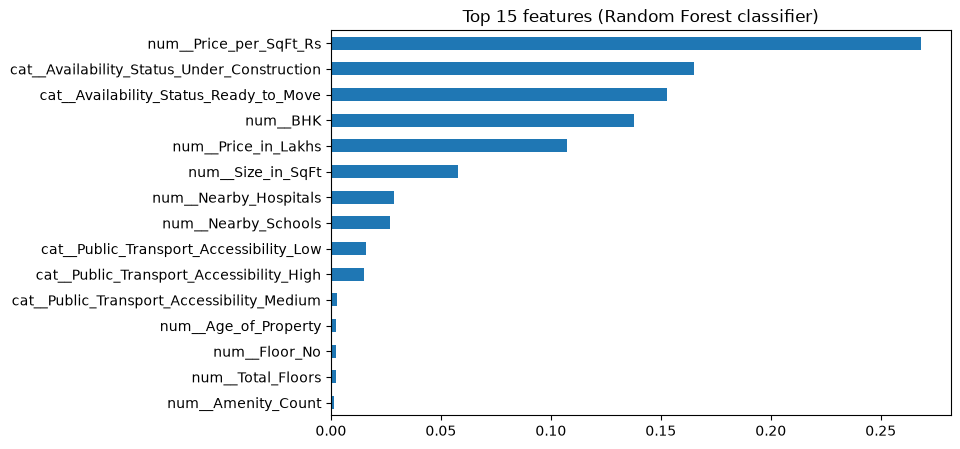

In [6]:
# More informative regression check: can the model predict the growth rate itself?
growth_pipe = Pipeline([("prep", make_preprocessor()),
                        ("model", XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                                               tree_method="hist", n_jobs=-1, random_state=42))])
growth_pipe.fit(X_train, yg_train)
gp = growth_pipe.predict(X_test)
print("Growth rate R2:", round(r2_score(yg_test, gp), 3), "| MAE:", round(mean_absolute_error(yg_test, gp), 4))

# Top features from the Random Forest classifier
rf = fitted_clf["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).nlargest(15)
imp.sort_values().plot(kind="barh", figsize=(8, 5), title="Top 15 features (Random Forest classifier)")

# Save the best models and the feature list for the Streamlit app
os.makedirs("../models", exist_ok=True)
best_clf = max(clf_results, key=lambda k: clf_results[k]["F1"])
best_reg = min(reg_results, key=lambda k: reg_results[k]["RMSE"])
joblib.dump(fitted_clf[best_clf], "../models/investment_classifier.joblib")
joblib.dump(fitted_reg[best_reg], "../models/price_regressor.joblib")
joblib.dump(features, "../models/feature_list.joblib")
print("Saved:", best_clf, "(classifier),", best_reg, "(regressor)")

In [7]:
print(pd.DataFrame(reg_results).T.round(4))

                      RMSE     MAE      R2
Linear Regression  11.5166  8.7726  0.9962
Random Forest      11.0428  7.9251  0.9965
XGBoost             9.3600  6.5744  0.9975
